In [ ]:
import os
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pandas import DataFrame
import re
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu

In [ ]:
# Paths are relative to the project folder: inputs in data/, files written by
# earlier notebooks in results/, figures in figures/.
DATA_DIR = 'data'
RESULTS_DIR = 'results'
FIGURE_DIR = 'figures'

# Input files
DRUG_AUC = f'{DATA_DIR}/beataml2_patients_drug.csv'
CLINICAL = f'{DATA_DIR}/beataml2_data.csv'
TRANSCELL_RESULTS = f'{DATA_DIR}/DECONVALID_results.csv'
DIST_DF = f'{RESULTS_DIR}/dist_df.csv'

# Output files
DRUG_ANNOT_OUT = f'{RESULTS_DIR}/drug_aml_annot.csv'
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

In [9]:
pat_df = pd.read_csv(DRUG_AUC).dropna()
pat_df = pd.crosstab(index=pat_df['OCTAD_drugs'], columns=pat_df['dbgap_subject_id'], values=pat_df['auc'], aggfunc='mean')
total_df = pd.read_csv(TRANSCELL_RESULTS, index_col=0)
list_patids = list(set([int(i[1]) for i in total_df.columns.str.split('_')]) & set(pat_df.columns))

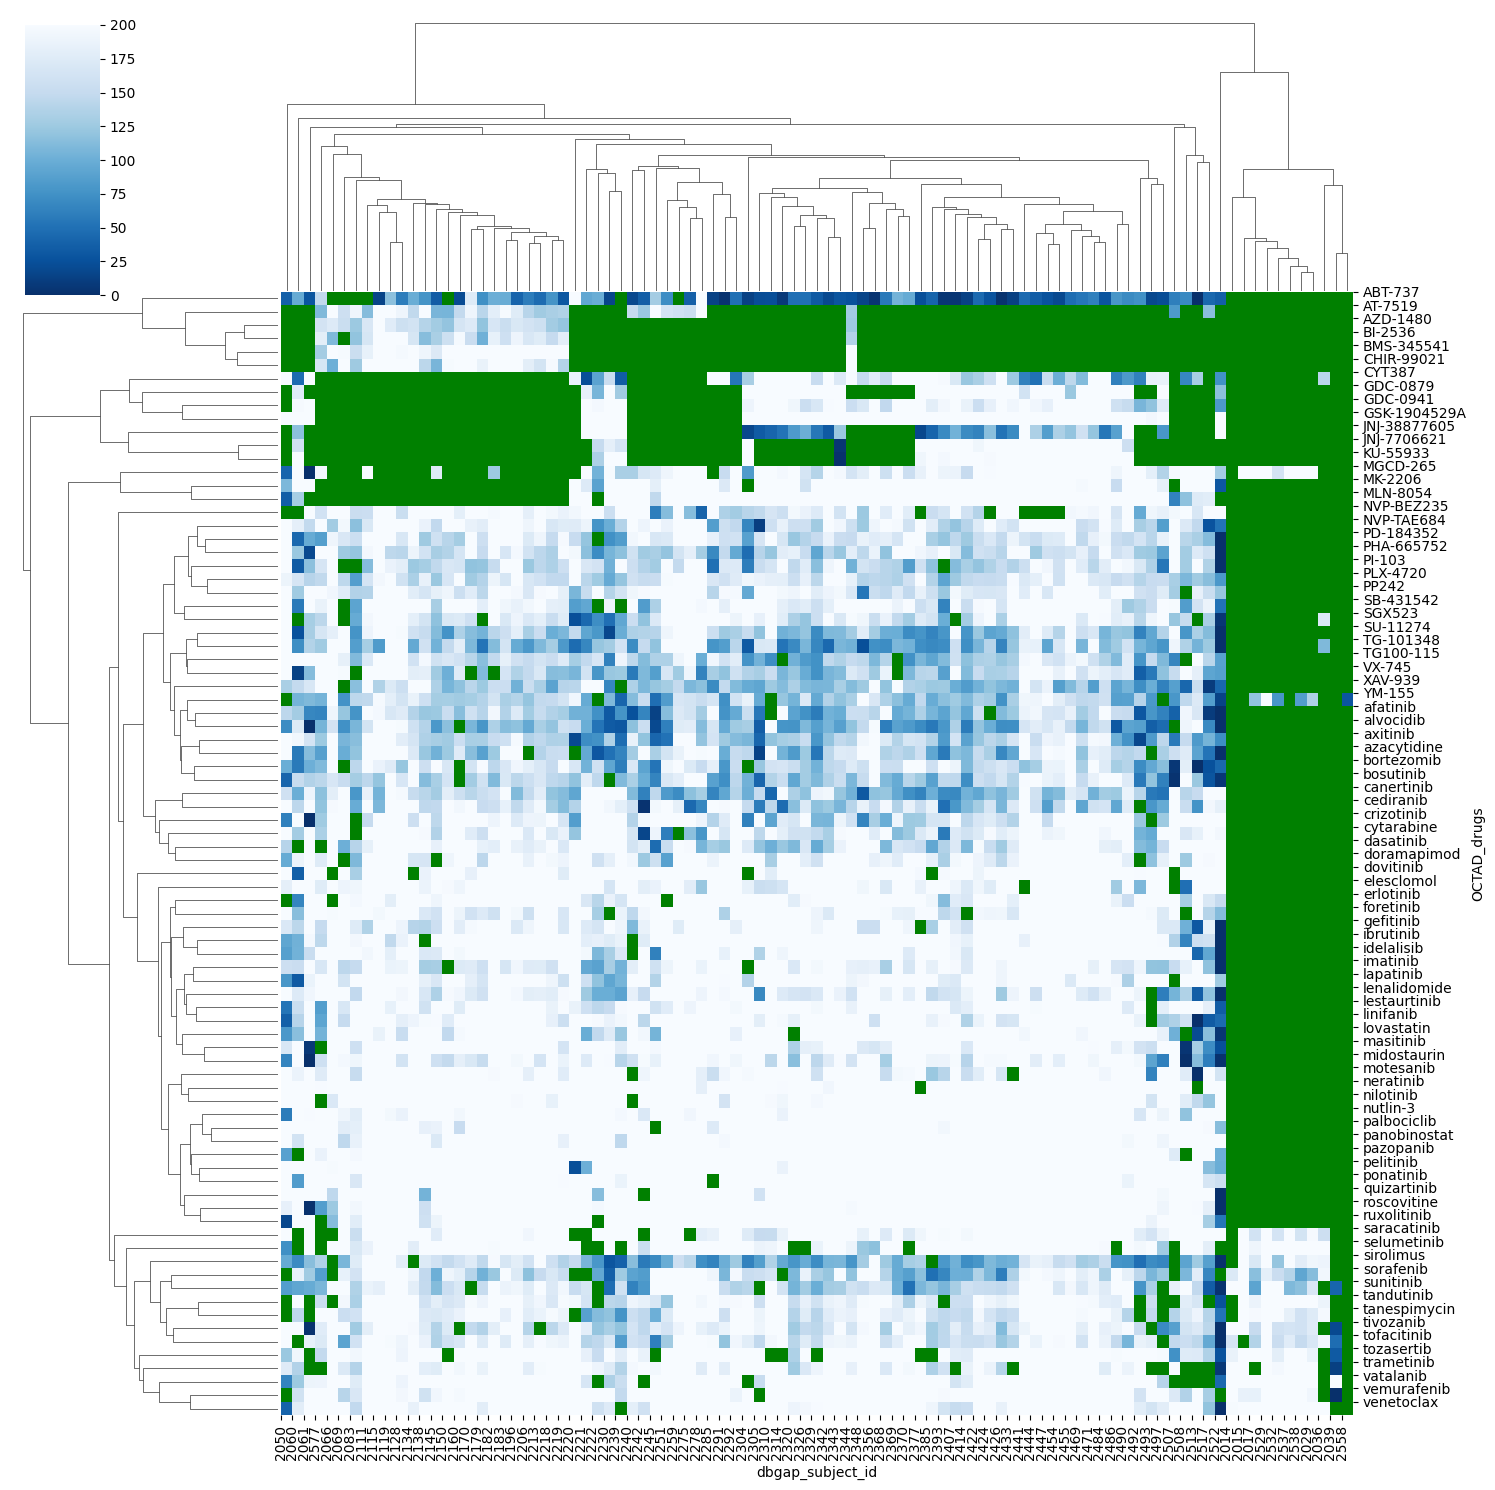

<Figure size 640x480 with 0 Axes>

In [ ]:
drugs_exvivo = pat_df[list_patids]
# Make a colormap where NaNs are black
cmap = sns.color_palette("Blues_r", as_cmap=True)
cmap.set_bad("green")

# Fill NaNs with a neutral number (e.g. 0) just for clustering
g = sns.clustermap(
    drugs_exvivo.fillna(0),
    cmap=cmap,
    mask=drugs_exvivo.isna(), vmax = 200, figsize=(15, 15)
)
g.ax_heatmap.set_xticks(range(len(drugs_exvivo.columns)))
g.ax_heatmap.set_xticklabels(drugs_exvivo.columns, rotation=90)
g.ax_heatmap.set_yticks(range(len(drugs_exvivo.index)))
g.ax_heatmap.set_yticklabels(drugs_exvivo.index)

plt.show()
plt.tight_layout()

In [11]:
drug_annot = drugs_exvivo < 100
drug_annot = drug_annot[drug_annot.sum(axis=1) > 2]
drug_annot = drug_annot[drug_annot.columns[drug_annot.sum() > 2]]
drug_annot.astype(int).to_csv(DRUG_ANNOT_OUT)

In [12]:
list_refs = list(set([i[0] for i in total_df.columns.str.split('_')]))

list_corr = []
for r in list_refs:
    bulk_one_ref = total_df[total_df.columns[total_df.columns.str.contains(r)]]

    list_pearson = []
    list_i = []
    for i in bulk_one_ref.columns:
        try:
            one_ref = DataFrame(bulk_one_ref[i])
            one_auc = DataFrame(pat_df[int(i.split('_')[1])])
            combined = pd.concat([one_ref, one_auc], axis=1).dropna()
            if len(combined.index) > 20:
                pearson = stats.spearmanr(combined[combined.columns[0]].values, combined[combined.columns[1]].values)
                list_pearson.append(pearson.statistic)
                list_i.append(int(i.split('_')[1]))
        except:
            continue
    list_corr.append(DataFrame(list_pearson, index=list_i, columns=[r]))
    print(r, np.median(list_pearson))

#P38, P14, P30, P23  good selection based on dist_df and failure rate
#P34, P25, P20, P36  bad selection based on dist_df and failure rate

P38 0.26781205453467205
P25 0.3925293899411897
P30 0.26274127213385867
P14 0.2871631126126277
Bulk 0.22130540021033251
P23 0.2817636525874778
P20 0.13451859191891963
P34 0.2842723369018627
P36 0.25050627164405775


In [14]:
pat_indiv = pd.concat(list_corr, axis=1).drop('Bulk', axis=1)
pat_access = pat_indiv.mean(axis=1).sort_values()

In [15]:
blast_frac = pd.read_csv(CLINICAL, index_col=0)[['%.Blasts.in.BM']].dropna()
com_ind = list(set(pat_access.index) & set(blast_frac.index))
blast_frac = blast_frac.loc[com_ind]
blast_frac = blast_frac[~blast_frac.index.duplicated(keep='first')].sort_values('%.Blasts.in.BM')
blast_frac['%.Blasts.in.BM'] = blast_frac['%.Blasts.in.BM'].astype(str).str.replace(r'[^0-9.]', '', regex=True).astype(float).values

comb_frac_corr = pd.concat([pat_access, blast_frac], axis=1).dropna()
stats.spearmanr(comb_frac_corr[comb_frac_corr.columns[0]].values, comb_frac_corr[comb_frac_corr.columns[1]].values)

SignificanceResult(statistic=-0.22914740955779803, pvalue=0.04798040589236447)

In [16]:
for p in pat_indiv.columns:
    comb_frac_indiv = pd.concat([pat_indiv[p], blast_frac], axis=1).dropna()
    print(p, stats.spearmanr(comb_frac_indiv[comb_frac_indiv.columns[0]].values, comb_frac_indiv[comb_frac_indiv.columns[1]].values))

P38 SignificanceResult(statistic=-0.2203028237329865, pvalue=0.05753304191287389)
P25 SignificanceResult(statistic=-0.22098646321702992, pvalue=0.05674332315788689)
P30 SignificanceResult(statistic=-0.2536017636016006, pvalue=0.028135445972612277)
P14 SignificanceResult(statistic=-0.19074965853736023, pvalue=0.10115405418561874)
P23 SignificanceResult(statistic=-0.20086182590550228, pvalue=0.08399614283175949)
P20 SignificanceResult(statistic=-0.25216327218725926, pvalue=0.02907118632557311)
P34 SignificanceResult(statistic=-0.20258516710486166, pvalue=0.08131698325079567)
P36 SignificanceResult(statistic=-0.2507675082406706, pvalue=0.03000406863472977)


In [17]:
bulk_access = pd.concat(list_corr, axis=1)[['Bulk']]
bulk_frac_corr = pd.concat([bulk_access, blast_frac], axis=1).dropna()
stats.spearmanr(bulk_frac_corr[bulk_frac_corr.columns[0]].values, bulk_frac_corr[bulk_frac_corr.columns[1]].values)

SignificanceResult(statistic=-0.043382622258254254, pvalue=0.7117041803037291)

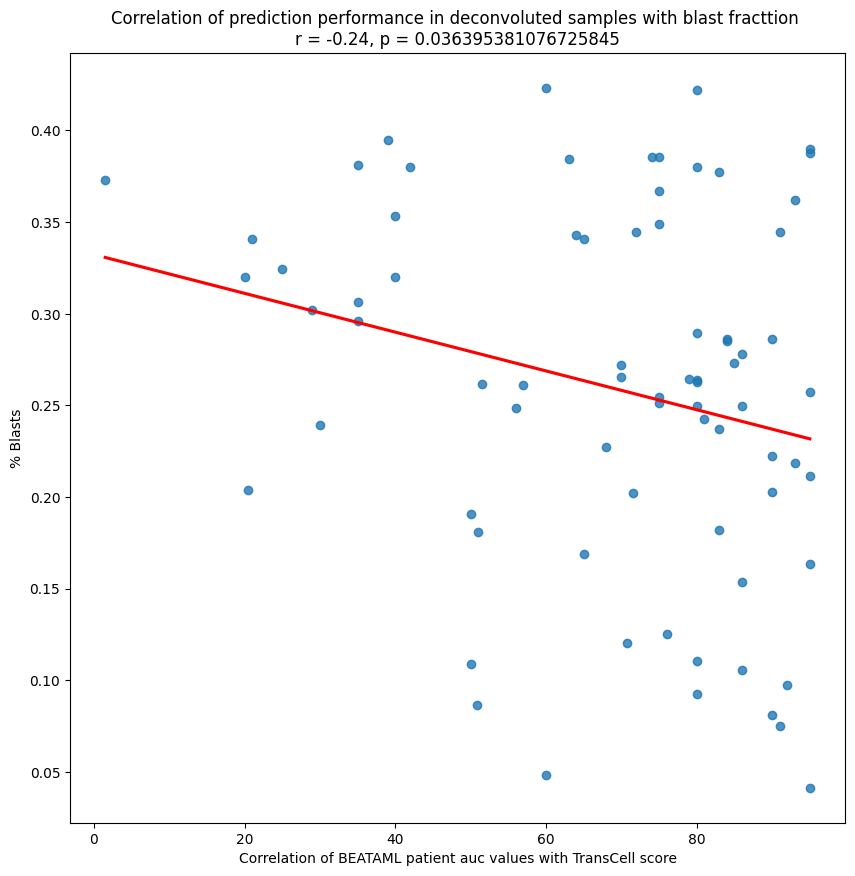

In [18]:
x = comb_frac_corr['%.Blasts.in.BM']
y = comb_frac_corr[0]

r, p = stats.pearsonr(x, y)

plt.figure(figsize=(10, 10))
sns.regplot(x=x, y=y, data=bulk_frac_corr, scatter=True, ci=None, line_kws={'color': 'red'})
plt.title(f'Correlation of prediction performance in deconvoluted samples with blast fracttion \nr = {r:.2f}, p = {p}')
plt.xlabel('Correlation of BEATAML patient auc values with TransCell score')
plt.ylabel('% Blasts')
plt.show()

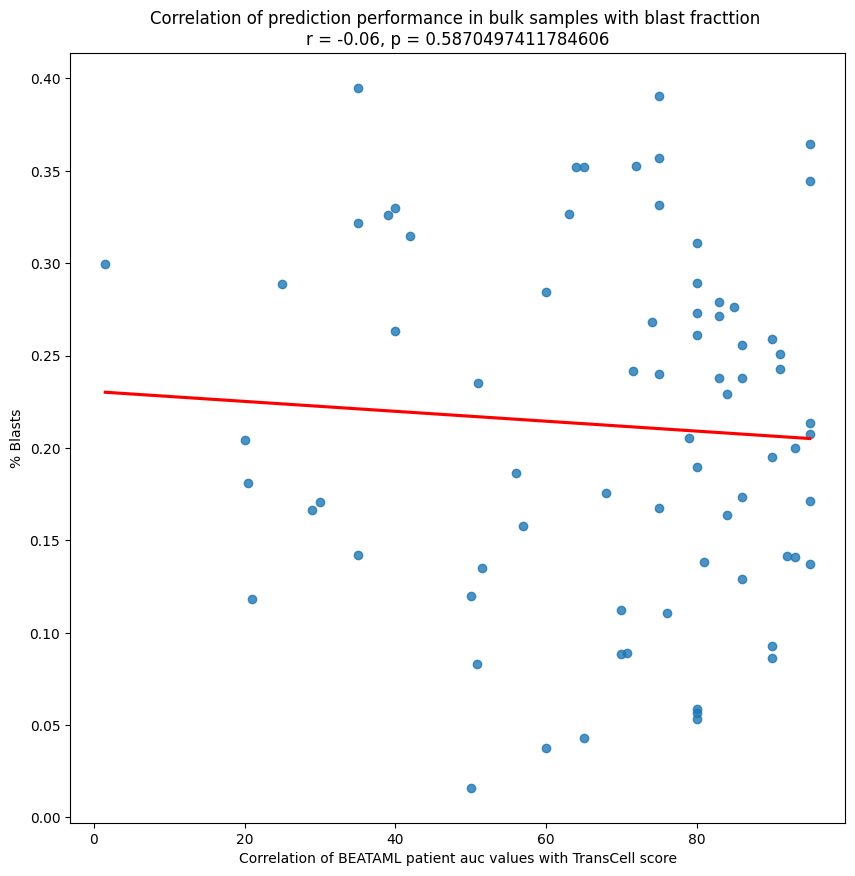

In [19]:
x = bulk_frac_corr['%.Blasts.in.BM']
y = bulk_frac_corr['Bulk']

r, p = stats.pearsonr(x, y)

plt.figure(figsize=(10, 10))
sns.regplot(x=x, y=y, data=bulk_frac_corr, scatter=True, ci=None, line_kws={'color': 'red'})
plt.title(f'Correlation of prediction performance in bulk samples with blast fracttion \nr = {r:.2f}, p = {p}')
plt.xlabel('Correlation of BEATAML patient auc values with TransCell score')
plt.ylabel('% Blasts')
plt.show()

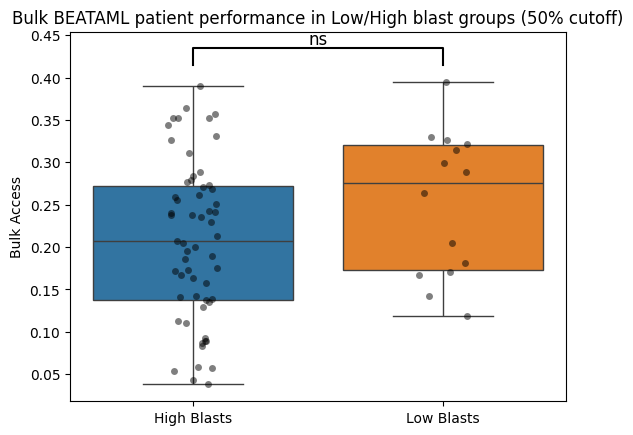

In [21]:
high_bulk = bulk_access.loc[blast_frac[blast_frac['%.Blasts.in.BM'] > 50].index].rename(columns={'Bulk':'Bulk High'})
low_bulk = bulk_access.loc[blast_frac[blast_frac['%.Blasts.in.BM'] < 50].index].rename(columns={'Bulk':'Bulk Low'})

# Prepare data
data = pd.concat([high_bulk, low_bulk])

t_stat, p_val = mannwhitneyu(data['Bulk High'], data['Bulk Low'], nan_policy='omit', alternative='two-sided')

# Function to convert p-value to stars
def p_to_stars(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

stars = p_to_stars(p_val)

# Boxplot + points
ax = sns.boxplot(data=data)
sns.stripplot(data=data, color='black', alpha=0.5, jitter=True)

# Labels
plt.xticks([0, 1], ['High Blasts', 'Low Blasts'])
plt.ylabel('Bulk Access')
plt.title('Bulk BEATAML patient performance in Low/High blast groups (50% cutoff)')

# Significance bar
x1, x2 = 0, 1
y, h = data.max().max() * 1.05, data.max().max() * 0.05
ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, color='k')
ax.text((x1+x2)/2, y+h, stars, ha='center', va='bottom', fontsize=12)

plt.show()

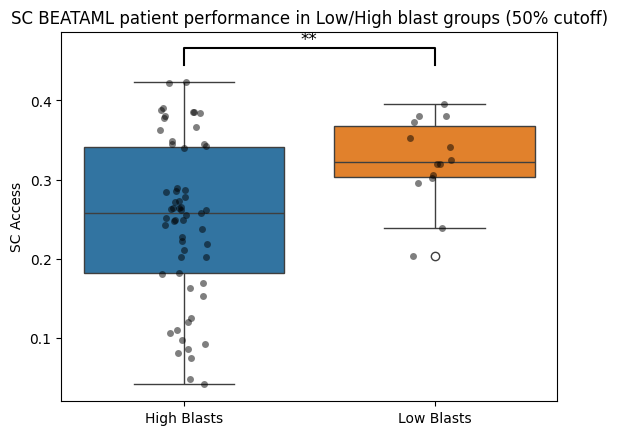

In [22]:
high_sc = DataFrame(pat_access).loc[blast_frac[blast_frac['%.Blasts.in.BM'] > 50].index].rename(columns={0:'SC High'})
low_sc = DataFrame(pat_access).loc[blast_frac[blast_frac['%.Blasts.in.BM'] < 50].index].rename(columns={0:'SC Low'})

# Prepare data
data = pd.concat([high_sc, low_sc])
# t-test

t_stat, p_val = mannwhitneyu(data['SC High'], data['SC Low'], nan_policy='omit')

# Function to convert p-value to stars
def p_to_stars(p):
    if p < 0.0001:
        return "****"
    elif p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"

stars = p_to_stars(p_val)

# Boxplot + points
ax = sns.boxplot(data=data)
sns.stripplot(data=data, color='black', alpha=0.5, jitter=True)

# Labels
plt.xticks([0, 1], ['High Blasts', 'Low Blasts'])
plt.ylabel('SC Access')
plt.title('SC BEATAML patient performance in Low/High blast groups (50% cutoff)')

# Significance bar
x1, x2 = 0, 1
y, h = data.max().max() * 1.05, data.max().max() * 0.05
ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, color='k')
ax.text((x1+x2)/2, y+h, stars, ha='center', va='bottom', fontsize=12)

plt.show()

/var/folders/3p/qzzcgxt56snd0tt5kns631pw0000gq/T/ipykernel_297/3242281965.py:24: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=melted, x='Reference', y='Correlation AUC vs Transcell', hue='GroupColor', color='black', size=3, jitter=True, alpha=0.7, legend = False)


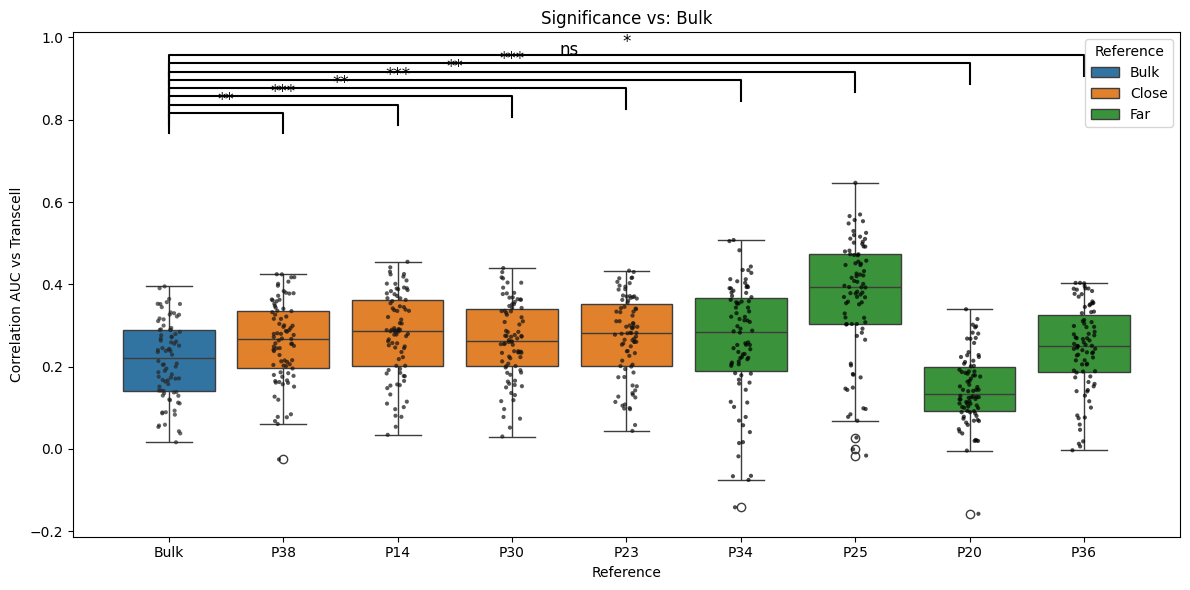

In [23]:
all_performance = pd.concat([bulk_access, pat_indiv[['P38', 'P14', 'P30', 'P23']], pat_indiv[['P34', 'P25', 'P20', 'P36']]], axis=1)

group_map = {
    'Bulk': 'Bulk',
    'P38': 'Close',
    'P14': 'Close',
    'P30': 'Close',
    'P23': 'Close',
    'P34': 'Far',
    'P25': 'Far',
    'P20': 'Far',
    'P36': 'Far'
}

# Melt the DataFrame
melted = all_performance.melt(var_name='Reference', value_name='Correlation AUC vs Transcell')

# Map groups for each row
melted['GroupColor'] = melted['Reference'].map(group_map)

# Plot with hue
plt.figure(figsize=(12, 6))
sns.boxplot(data=melted, x='Reference', y='Correlation AUC vs Transcell', hue='GroupColor')
sns.stripplot(data=melted, x='Reference', y='Correlation AUC vs Transcell', hue='GroupColor', color='black', size=3, jitter=True, alpha=0.7, legend = False)

# First column to compare against
first_col = all_performance.columns[0]
y_max = melted['Correlation AUC vs Transcell'].max()

def pval_to_star(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

# Loop and add annotations
for i, col in enumerate(all_performance.columns[1:], start=1):
    
    t_stat, p_val = mannwhitneyu(all_performance[first_col], all_performance[col], nan_policy='omit', alternative='less')

    stars = pval_to_star(p_val)
    x1, x2 = 0, i
    y, h = y_max + 0.1 + i*0.02, 0.05
    plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, c='k')
    plt.text((x1 + x2) * 0.5, y + h + 0.01, stars, ha='center', va='bottom', fontsize=12)

plt.title(f"Significance vs: {first_col}")
plt.legend(title='Reference', loc='upper right')
plt.tight_layout()
plt.show()

#P38, P14, P30, P23  good selection based on dist_df and failure rate
#P34, P25, P20, P36  bad selection based on dist_df and failure rate

In [25]:
dist_df = pd.read_csv(DIST_DF, index_col=0)

good_dict = {}

for row in dist_df.index:
    paired_cols = dist_df.loc[row][dist_df.loc[row] < 10].index.tolist()
    good_dict[row] = paired_cols

new_list = [x for x in list_refs if x != 'Bulk']

list_corr_sel = []

for r in new_list:
    pattern = '|'.join(map(re.escape, good_dict[r]))

    bulk_one_ref = total_df[total_df.columns[total_df.columns.str.contains(r)]]
    bulk_one_ref = bulk_one_ref[bulk_one_ref.columns[bulk_one_ref.columns.str.contains(pattern)]]

    list_pearson = []
    list_i = []
    for i in bulk_one_ref.columns:
        try:
            one_ref = DataFrame(bulk_one_ref[i])
            one_auc = DataFrame(pat_df[int(i.split('_')[1])])
            combined = pd.concat([one_ref, one_auc], axis=1).dropna()
            if len(combined.index) > 20:
                pearson = stats.pearsonr(combined[combined.columns[0]].values, combined[combined.columns[1]].values)
                list_pearson.append(pearson.statistic)
                list_i.append(int(i.split('_')[1]))
        except:
            continue
    list_corr_sel.append(DataFrame(list_pearson, index=list_i, columns=[r]))
    print(r, np.median(list_pearson))

#P38, P14, P30, P23  good selection based on dist_df and failure rate
#P34, P25, P20, P36  bad selection based on dist_df and failure rate

P38 0.3426947431073617
P25 0.41804428149586303
P30 0.28616000662759633
P14 0.2862432287996594
P23 0.27819830332597456
P20 0.22904240735315695
P34 0.3747839614981467
P36 0.3187888086442324


In [26]:
sel_dist = dist_df.T.loc[list(set(pat_indiv.index.astype(str)) & set(dist_df.T.index))][['P38', 'P14', 'P30', 'P23', 'P34', 'P25', 'P20', 'P36']]
sel_dist
sel_min = sel_dist.where(sel_dist.eq(sel_dist.min(axis=1), axis=0))
sel_min.index = sel_min.index.astype(int)
sel_pat = pat_indiv[sel_dist.columns].loc[sel_min.index]
sel_perf = sel_pat.where(sel_min.notna())
sel_noperf = sel_pat.where(sel_min.isna())

/var/folders/3p/qzzcgxt56snd0tt5kns631pw0000gq/T/ipykernel_297/1113308706.py:26: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=melted, x='Reference', y='Correlation AUC vs Transcell', hue='GroupColor', color='black', size=3, jitter=True, alpha=0.7, legend = False)


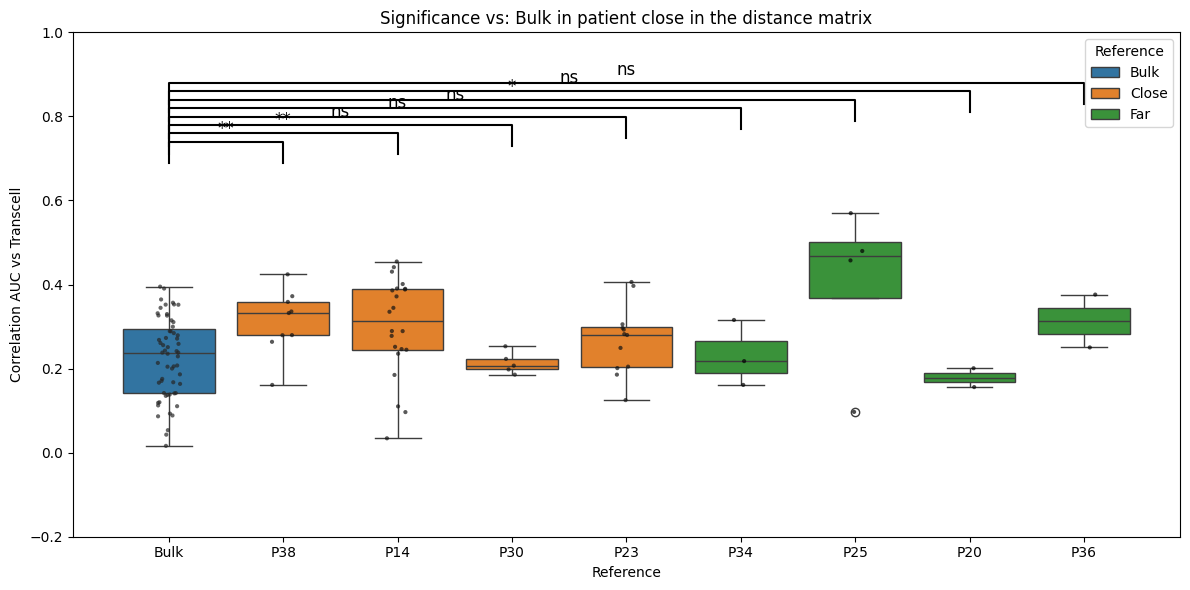

In [28]:
sel_performance = pd.concat([bulk_access, sel_perf[['P38', 'P14', 'P30', 'P23']], sel_perf[['P34', 'P25', 'P20', 'P36']]], axis=1)
sel_performance = sel_performance.dropna(thresh=2)

group_map = {
    'Bulk': 'Bulk',
    'P38': 'Close',
    'P14': 'Close',
    'P30': 'Close',
    'P23': 'Close',
    'P34': 'Far',
    'P25': 'Far',
    'P20': 'Far',
    'P36': 'Far'
}

# Melt the DataFrame
melted = sel_performance.melt(var_name='Reference', value_name='Correlation AUC vs Transcell')

# Map groups for each row
melted['GroupColor'] = melted['Reference'].map(group_map)

# Plot with hue
plt.figure(figsize=(12, 6))
sns.boxplot(data=melted, x='Reference', y='Correlation AUC vs Transcell', hue='GroupColor')
sns.stripplot(data=melted, x='Reference', y='Correlation AUC vs Transcell', hue='GroupColor', color='black', size=3, jitter=True, alpha=0.7, legend = False)

# First column to compare against
first_col = sel_performance.columns[0]
y_max = melted['Correlation AUC vs Transcell'].max()

def pval_to_star(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

# Loop and add annotations
for i, col in enumerate(sel_performance.columns[1:], start=1):
    
    t_stat, p_val = mannwhitneyu(sel_performance[first_col], sel_performance[col], nan_policy='omit', alternative='less')

    stars = pval_to_star(p_val)
    x1, x2 = 0, i
    y, h = y_max + 0.1 + i*0.02, 0.05
    plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, c='k')
    plt.text((x1 + x2) * 0.5, y + h + 0.01, stars, ha='center', va='bottom', fontsize=12)

plt.ylim(-0.2, 1)
plt.title(f"Significance vs: {first_col} in patient close in the distance matrix")
plt.legend(title='Reference', loc='upper right')
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/performance_sig_close.pdf')
plt.show()

#P38, P14, P30, P23  good selection based on dist_df and failure rate
#P34, P25, P20, P36  bad selection based on dist_df and failure rate

/var/folders/3p/qzzcgxt56snd0tt5kns631pw0000gq/T/ipykernel_297/1747624834.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=melted, x='GroupBox', y='Correlation AUC vs Transcell', palette=palette_colors)


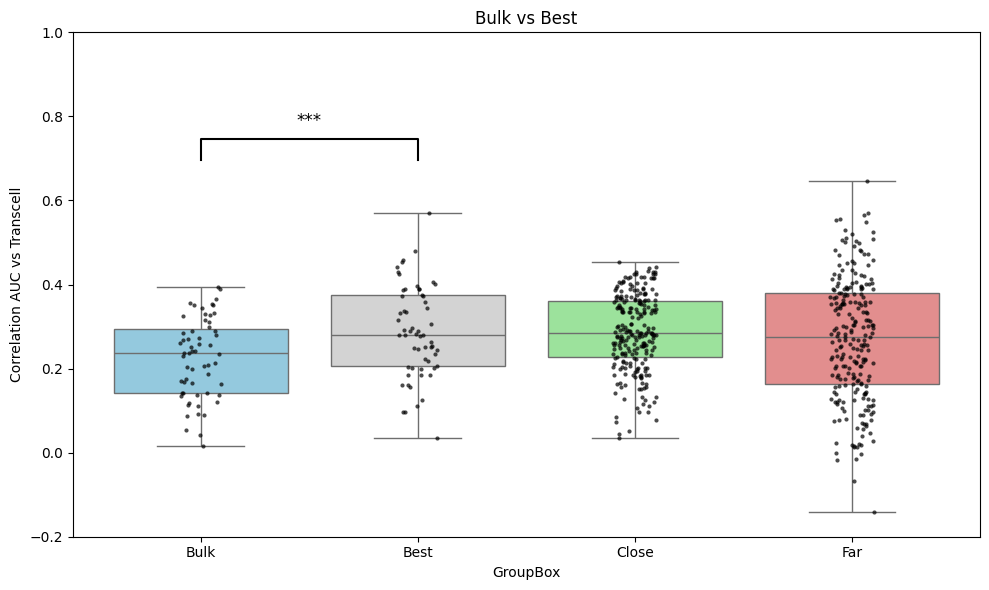

In [29]:
# Melt the DataFrame
melted = sel_performance.melt(var_name='Reference', value_name='Correlation AUC vs Transcell')

# Two groups: Bulk vs Best
melted['GroupBox'] = melted['Reference'].apply(lambda x: 'Bulk' if x == 'Bulk' else 'Best')

melted_b = all_performance.loc[sel_performance.index].drop('Bulk', axis=1).melt(var_name='Reference', value_name='Correlation AUC vs Transcell')

# Map references to groups
group_map = {
    'Bulk': 'Bulk',
    'P38': 'Close',
    'P14': 'Close',
    'P30': 'Close',
    'P23': 'Close',
    'P34': 'Far',
    'P25': 'Far',
    'P20': 'Far',
    'P36': 'Far'
}
melted_b['GroupBox'] = melted_b['Reference'].map(group_map).fillna('Best')
melted = pd.concat([melted, melted_b]).dropna()
# Plot
plt.figure(figsize=(10, 6))
palette_colors = {'Bulk': 'skyblue', 'Close': 'lightgreen', 'Far': 'lightcoral', 'Best': 'lightgrey'}
sns.boxplot(data=melted, x='GroupBox', y='Correlation AUC vs Transcell', palette=palette_colors)

sns.stripplot(data=melted, x='GroupBox', y='Correlation AUC vs Transcell', color='black', size=3, jitter=True, alpha=0.7)

# Optional: annotate significance (Bulk vs Best)
bulk_vals = sel_performance['Bulk']
best_vals = sel_performance[[c for c in sel_performance.columns if c != 'Bulk']].values.flatten()
bulk_vals = bulk_vals[~bulk_vals.isna()]
best_vals = best_vals[~pd.isna(best_vals)]

t_stat, p_val = ttest_ind(bulk_vals, best_vals, nan_policy='omit', alternative='less')

def pval_to_star(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

y_max = melted['Correlation AUC vs Transcell'].max()
stars = pval_to_star(p_val)
plt.plot([0, 0, 1, 1], [y_max+0.05, y_max+0.1, y_max+0.1, y_max+0.05], lw=1.5, c='k')
plt.text(0.5, y_max+0.12, stars, ha='center', va='bottom', fontsize=12)

plt.ylim(-0.2, 1)
plt.title("Bulk vs Best")
plt.tight_layout()
plt.savefig(f'{FIGURE_DIR}/performance_best.pdf')
plt.show()

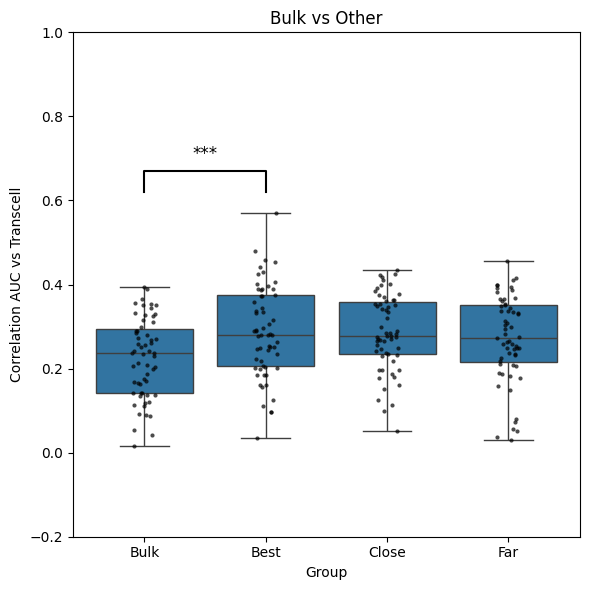

In [30]:
# Melt the DataFrame
melted = sel_performance.melt(var_name='Reference', value_name='Correlation AUC vs Transcell')

dfcf1 = DataFrame(all_performance[['P38', 'P14', 'P30', 'P23']].mean(axis=1), columns=['Close'])
dfcf2 = DataFrame(all_performance[['P34', 'P25', 'P20', 'P36']].mean(axis=1), columns=['Far'])

dfcf = pd.concat([dfcf1, dfcf2], axis=1)
dfcf = dfcf.loc[sel_performance.index]

# Two groups: Bulk vs Other
melted['Group'] = melted['Reference'].apply(lambda x: 'Bulk' if x == 'Bulk' else 'Best')

melted_b = dfcf.melt(var_name='Reference', value_name='Correlation AUC vs Transcell')

melted_b['Group'] = melted_b['Reference']
melted = pd.concat([melted, melted_b]).dropna()
# Plot
plt.figure(figsize=(6, 6))
sns.boxplot(data=melted, x='Group', y='Correlation AUC vs Transcell')
sns.stripplot(data=melted, x='Group', y='Correlation AUC vs Transcell', color='black', size=3, jitter=True, alpha=0.7)

# Optional: annotate significance (Bulk vs Other)
bulk_vals = sel_performance['Bulk']
other_vals = sel_performance[[c for c in sel_performance.columns if c != 'Bulk']].values.flatten()
bulk_vals = bulk_vals[~bulk_vals.isna()]
other_vals = other_vals[~pd.isna(other_vals)]

t_stat, p_val = ttest_ind(bulk_vals, other_vals, nan_policy='omit', alternative='less')

def pval_to_star(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

y_max = melted['Correlation AUC vs Transcell'].max()
stars = pval_to_star(p_val)
plt.plot([0, 0, 1, 1], [y_max+0.05, y_max+0.1, y_max+0.1, y_max+0.05], lw=1.5, c='k')
plt.text(0.5, y_max+0.12, stars, ha='center', va='bottom', fontsize=12)

plt.ylim(-0.2, 1)
plt.title("Bulk vs Other")
plt.tight_layout()
plt.show()